# Cookie Cats: Mobile Game A/B Test Analysis

**Does moving the first gate from level 30 to level 40 change player retention?**

*Cookie Cats* is a mobile puzzle game. As players progress, they reach **gates** that force them to wait or make an in-app purchase before they can continue. The developers ran an A/B test with **90,189 new players**, moving the first gate from **level 30** to **level 40**. This notebook measures the effect of that change on **1-day and 7-day retention** using **Wilson confidence intervals**, a **two-proportion z-test** and **confidence intervals for the treatment effect**.

> **Dataset:** [Mobile Games A/B Testing: Cookie Cats](https://www.kaggle.com/datasets/mursideyarkin/mobile-games-ab-testing-cookie-cats) (Kaggle) &nbsp;|&nbsp; **Tools:** Python · pandas · statsmodels · SciPy · seaborn

---

## 📑 Table of Contents

| # | Section | Description |
|:-:|:--|:--|
| 1 | 🎯 [Project Goal & Target Metric](#goal) | Business context, target metrics and hypotheses |
| 2 | ⚙️ [Setup](#setup) | Libraries used in the analysis |
| 3 | 📥 [Data Loading & Validation](#data) | Loading the dataset and checking data quality |
| 4 | 🔍 [Exploratory Analysis](#eda) | Distribution of game rounds and choice of metric |
| 5 | 📊 [Statistical Analysis](#analysis) | Sample sizes, retention rates and confidence intervals |
| 6 | 🔬 [Two-Proportion z-Test](#ztest) | Testing the difference in retention between versions |
| 7 | 📏 [Treatment Effect](#effect) | Size of the effect and its confidence interval |
| 8 | ✅ [Conclusions & Recommendation](#conclusions) | Key findings and business decision |

---

<a id="goal"></a>
## 1. Project Goal & Target Metric

### Business context
In *Cookie Cats*, gates are a key part of the game design: they pause progress, which can make players take a break and come back later, or push them toward an in-app purchase. The first gate was originally placed at **level 30**. To see whether its position affects player engagement, new players were randomly assigned to one of two versions:

- **`gate_30` (control):** the first gate is at level 30.
- **`gate_40` (treatment):** the first gate is moved to level 40.

### Goal
Determine whether moving the first gate to level 40 changes how many players keep playing and, based on that, which version the game should use.

### Target metrics
- **`retention_1`**: share of players who came back and played **1 day** after installing.
- **`retention_7`**: share of players who came back and played **7 days** after installing.

Retention measures directly whether players stay engaged with the game, which is what the gate position is expected to affect. Day-7 retention is the more important of the two, because it reflects longer-term engagement. Section 4 explains why the number of game rounds was not chosen as the target metric.

### Hypotheses (for each metric)
- **H₀:** The retention rate is the same for `gate_30` and `gate_40`.
- **H₁:** The retention rate differs between `gate_30` and `gate_40`.

<a id="setup"></a>
## 2. Setup

The analysis uses `kagglehub` to download the data, `pandas` and `numpy` for data handling, `matplotlib` and `seaborn` for visualization, and `statsmodels` and `scipy` for the statistical tests.

In [34]:
import kagglehub
import pandas as pd
import os
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import seaborn as sns
from scipy.stats import norm
import numpy as np
from statsmodels.stats.proportion import (
    proportions_ztest, proportion_confint, confint_proportions_2indep
)

<a id="data"></a>
## 3. Data Loading & Validation

The dataset is downloaded directly from Kaggle. It contains **90,189 players** who installed the game while the A/B test was running. Each row is one player:

| Column | Description |
|:--|:--|
| `userid` | Unique identifier of the player |
| `version` | Group the player was assigned to: `gate_30` (control) or `gate_40` (treatment) |
| `sum_gamerounds` | Number of game rounds played during the first 14 days after installing |
| `retention_1` | Whether the player came back and played 1 day after installing |
| `retention_7` | Whether the player came back and played 7 days after installing |

In [35]:
path = kagglehub.dataset_download("mursideyarkin/mobile-games-ab-testing-cookie-cats")
cookie_cats = pd.read_csv(os.path.join(path, "cookie_cats.csv"))

cookie_cats.sample(5)

,userid,version,sum_gamerounds,retention_1,retention_7
81833,9067190,gate_30,20,True,False
8553,942545,gate_40,12,True,False
69171,7667227,gate_40,25,False,False
76992,8526620,gate_30,22,False,False
89130,9881532,gate_30,10,False,False


Before the analysis, the data is checked for **missing values** (as a percentage of rows) and **data types**.

In [36]:
(cookie_cats.isna().sum()) * 100 / len(cookie_cats)

userid            0.0
version           0.0
sum_gamerounds    0.0
retention_1       0.0
retention_7       0.0
dtype: float64

In [37]:
cookie_cats.dtypes

userid            int64
version             str
sum_gamerounds    int64
retention_1        bool
retention_7        bool
dtype: object

✔️ There are **no missing values**, and every feature has the appropriate data type: the retention columns are booleans, so their mean is directly the retention rate. No additional cleaning is required.

<a id="eda"></a>
## 4. Exploratory Analysis

The first candidate metric is `sum_gamerounds`, the number of rounds each player played during the first 14 days. The plots below show its distribution on a **logarithmic scale**, because the values range from a few rounds to tens of thousands.

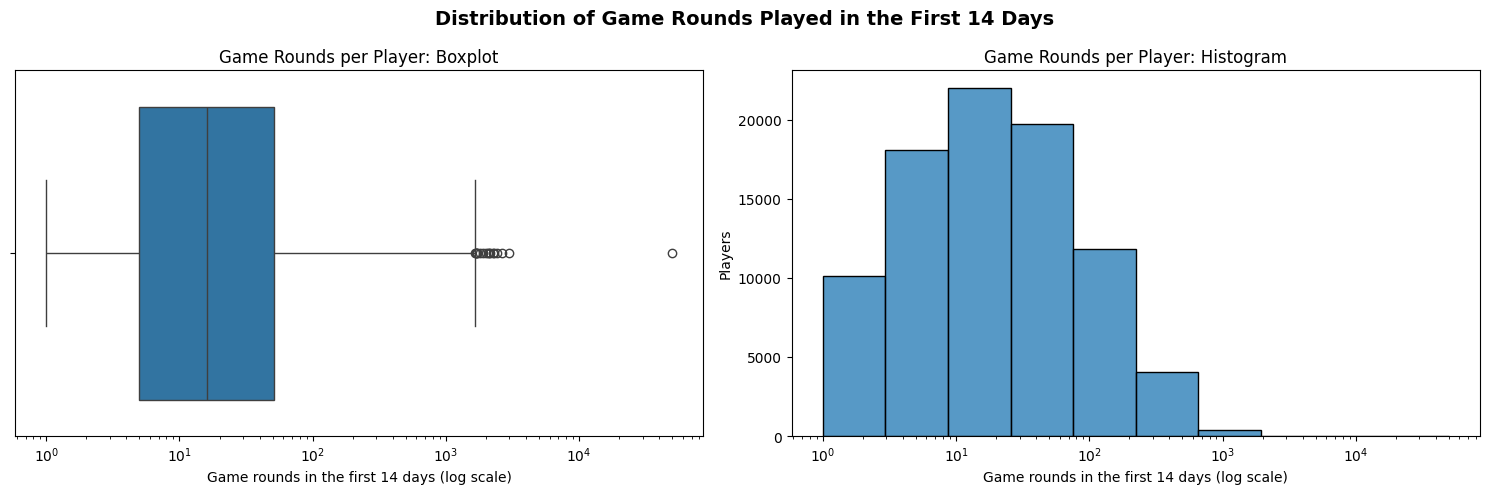

In [38]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))
sns.boxplot(data=cookie_cats, x="sum_gamerounds", log_scale=True, ax=ax[0])
ax[0].set_title("Game Rounds per Player: Boxplot")
ax[0].set_xlabel("Game rounds in the first 14 days (log scale)")
sns.histplot(data=cookie_cats, x="sum_gamerounds", log_scale=True, bins=10, ax=ax[1])
ax[1].set_title("Game Rounds per Player: Histogram")
ax[1].set_xlabel("Game rounds in the first 14 days (log scale)")
ax[1].set_ylabel("Players")
fig.suptitle("Distribution of Game Rounds Played in the First 14 Days", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

**Observations**
- `sum_gamerounds` is **extremely skewed** and has a very high variance: half of the players play 16 rounds or fewer, while a few play tens of thousands. Players with 0 rounds cannot be shown on a log scale, so they are left out of the plots.
- With such a spread, the average number of rounds is driven by a handful of extreme players and does not describe the typical player well.
- The A/B test is about whether players **keep coming back** to the game. So the analysis focuses on the **retention metrics** (`retention_1` and `retention_7`) as the target metrics, rather than on the number of rounds played.

<a id="analysis"></a>
## 5. Statistical Analysis

### Significance level
With the metrics defined, the next step is to set the significance level. The base level is **α = 0.05**, but the analysis runs **two two-sided tests**, one for each retention metric. To keep the overall false-positive rate at 5%, the **Bonferroni correction** is applied:

$$\alpha_{adj} = \frac{0.05}{2} = 0.025$$

All tests and confidence intervals below use this adjusted level, so the intervals are **97.5% confidence intervals**.

In [39]:
ALPHA = 0.025
metrics = ['retention_1', 'retention_7']
METRIC_LABELS = {'retention_1': 'Day-1 Retention', 'retention_7': 'Day-7 Retention'}

### Sample size per version
The first check is how many players were assigned to each version.

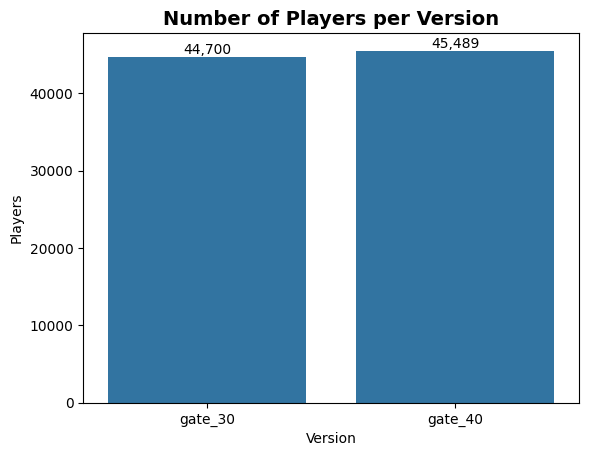

In [40]:
count = cookie_cats['version'].value_counts().sort_index()
ax = sns.barplot(x=count.index, y=count.values)
ax.bar_label(ax.containers[0], fmt='{:,.0f}')
ax.set_title('Number of Players per Version', fontsize=14, fontweight='bold')
ax.set_xlabel('Version')
ax.set_ylabel('Players')
plt.show()

The two groups have a similar size: **44,700 players (49.6%)** in `gate_30` and **45,489 players (50.4%)** in `gate_40`. Both groups are large, which gives the tests below high precision.

### Retention rate by version
The plot below shows the retention rate of each version with its **97.5% Wilson confidence interval**. Retention is a binary outcome (1 = the player came back, 0 = the player did not), so its mean is the share of players retained.

        metric  version      rate        lo        hi
0  retention_1  gate_30  0.448188  0.442922  0.453466
1  retention_1  gate_40  0.442283  0.437070  0.447508
2  retention_7  gate_30  0.190201  0.186076  0.194397
3  retention_7  gate_40  0.182000  0.177980  0.186090


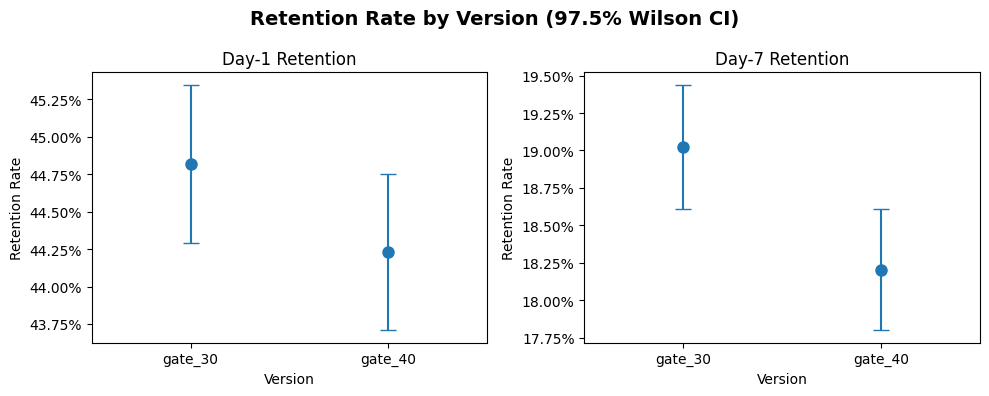

In [41]:
rows = []
for m in metrics:
    for v, g in cookie_cats.groupby('version'):
        k, n = g[m].sum(), len(g)
        lo, hi = proportion_confint(k, n, alpha=ALPHA, method='wilson')
        rows.append(dict(metric=m, version=v, rate=k/n, lo=lo, hi=hi))
res = pd.DataFrame(rows)
print(res)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, m in zip(axes, metrics):
    d = res[res.metric == m]
    ax.errorbar(d.version, d.rate,
                yerr=[d.rate - d.lo, d.hi - d.rate],
                fmt='o', capsize=6, markersize=8)
    ax.set_title(METRIC_LABELS[m])
    ax.set_xlabel('Version')
    ax.set_ylabel('Retention Rate')
    ax.margins(x=0.5)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
fig.suptitle(f'Retention Rate by Version ({1 - ALPHA:.1%} Wilson CI)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**Observations**
- **Day-1 retention:** `gate_30` retains 44.8% of players and `gate_40` retains 44.2%. The confidence intervals **overlap**, which suggests there may be no real difference between the versions.
- **Day-7 retention:** `gate_30` retains 19.0% of players and `gate_40` retains 18.2%. The intervals **barely touch** and the means are further apart, which suggests that `gate_40` may retain fewer players after a week.

Overlapping intervals are only a visual hint, not a formal test. The next section tests these differences directly.

<a id="ztest"></a>
## 6. Two-Proportion z-Test

### Why a two-proportion z-test?
- Each retention metric is a **proportion** (the share of players who came back).
- The two groups are **independent**, since each player was randomly assigned to one version only.
- Both samples are **very large** (over 44,000 players each), so the sampling distribution of the difference in proportions is approximately normal.

The test is **two-sided**, since moving the gate could either increase or decrease retention, and it uses α = 0.025.

retention_1: z = 1.784, p = 0.0744
retention_7: z = 3.164, p = 0.0016


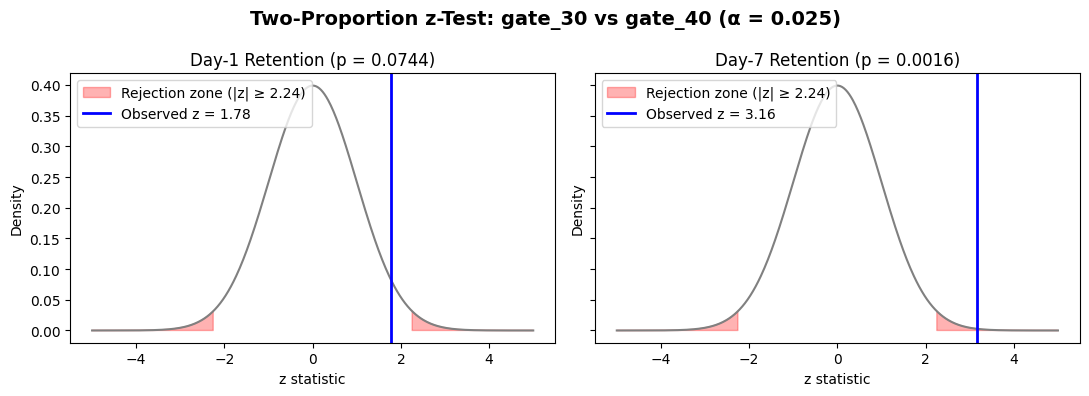

In [42]:
z_results = {}
for m in metrics:
    successes = cookie_cats.groupby('version')[m].sum()
    n = cookie_cats.groupby('version')[m].count()
    z, p = proportions_ztest(successes, n)
    z_results[m] = (z, p)
    print(f"{m}: z = {z:.3f}, p = {p:.4f}")

x = np.linspace(-5, 5, 500)
crit = norm.ppf(1 - ALPHA / 2)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, m in zip(axes, metrics):
    z, p = z_results[m]
    ax.plot(x, norm.pdf(x), color='gray')
    ax.fill_between(x, norm.pdf(x), where=(abs(x) >= crit),
                    alpha=0.3, color='red', label=f'Rejection zone (|z| ≥ {crit:.2f})')
    ax.axvline(z, color='blue', lw=2, label=f'Observed z = {z:.2f}')
    ax.set_title(f'{METRIC_LABELS[m]} (p = {p:.4f})')
    ax.set_xlabel('z statistic')
    ax.set_ylabel('Density')
    ax.legend(loc='upper left')
fig.suptitle(f'Two-Proportion z-Test: gate_30 vs gate_40 (α = {ALPHA})', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Results

| Metric | z | p-value | Significant at α = 0.025? |
|:--|--:|--:|:-:|
| Day-1 retention | 1.78 | 0.0744 | ✖️ No |
| Day-7 retention | 3.16 | 0.0016 | ✔️ Yes |

1. **Day-1 retention:** the observed z falls outside the rejection zone, so there is **not enough evidence to reject H₀**. The gate position has no detectable effect on whether players return the next day.
2. **Day-7 retention:** the observed z falls inside the rejection zone, so **H₀ is rejected**. Players who start with the gate at level 30 have a **higher 7-day retention** than players with the gate at level 40.

<a id="effect"></a>
## 7. Treatment Effect

Knowing that a difference exists is not enough. It is more important to know **how large** the difference is and how it affects the game. The treatment effect is the difference in retention, **`gate_40` − `gate_30`**, with its **97.5% confidence interval**.

        metric  difference        lo        hi
0  retention_1   -0.005905 -0.013324  0.001514
1  retention_7   -0.008201 -0.014011 -0.002392


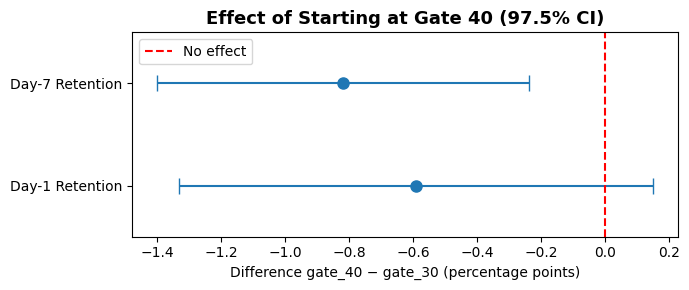

In [43]:
diffs = []
for m in metrics:
    successes = cookie_cats.groupby('version')[m].sum()
    n = cookie_cats.groupby('version')[m].count()
    low, upp = confint_proportions_2indep(
        successes['gate_40'], n['gate_40'],
        successes['gate_30'], n['gate_30'],
        method='wald', alpha=ALPHA
    )
    d = successes['gate_40'] / n['gate_40'] - successes['gate_30'] / n['gate_30']
    diffs.append(dict(metric=m, difference=d, lo=low, hi=upp))
diffs = pd.DataFrame(diffs)
print(diffs)

fig, ax = plt.subplots(figsize=(7, 3))
ax.errorbar(diffs['difference'] * 100, diffs['metric'].map(METRIC_LABELS),
            xerr=[(diffs['difference'] - diffs['lo']) * 100, (diffs['hi'] - diffs['difference']) * 100],
            fmt='o', capsize=6, markersize=8)
ax.axvline(0, color='red', ls='--', label='No effect')
ax.set_xlabel('Difference gate_40 − gate_30 (percentage points)')
ax.margins(y=0.5)
ax.set_title(f'Effect of Starting at Gate 40 ({1 - ALPHA:.1%} CI)', fontsize=13, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

| Metric | Effect (gate_40 − gate_30) | 97.5% CI | Includes zero? |
|:--|--:|:-:|:-:|
| Day-1 retention | −0.59 pp | −1.33 to +0.15 pp | ✔️ Yes |
| Day-7 retention | −0.82 pp | −1.40 to −0.24 pp | ✖️ No |

- **Day-1 retention:** the interval includes zero, which is consistent with the non-significant z-test.
- **Day-7 retention:** the whole interval is below zero. Moving the gate to level 40 means **between 0.24 and 1.40 percentage points fewer players** come back after seven days. The point estimate of −0.82 pp is a drop of about **4% in relative terms** (from 19.0% to 18.2%). This effect is small per player but meaningful for a game with a large player base.

<a id="conclusions"></a>
## 8. Conclusions & Recommendation

### Key findings
1. **The data is clean.** The dataset covers 90,189 players with no missing values, split into two groups of similar size (44,700 in `gate_30`, 45,489 in `gate_40`).
2. **Retention is the right target metric.** The number of game rounds is extremely skewed, while retention measures directly whether players keep playing.
3. **Day-1 retention does not change.** The difference (−0.59 pp) is not significant (z = 1.78, p = 0.074), and its 97.5% CI includes zero.
4. **Day-7 retention drops with the gate at level 40.** The difference (−0.82 pp) is significant (z = 3.16, p = 0.0016), even with the Bonferroni-adjusted α = 0.025.
5. **The effect is small but real.** With 97.5% confidence, moving the gate to level 40 lowers 7-day retention by **0.24 to 1.40 percentage points**.

### Recommendation
- ✔️ **Keep the first gate at level 30.** It retains more players after one week, which is the metric that best reflects long-term engagement.
- ✖️ **Do not move the gate to level 40.** It brings no benefit in day-1 retention and lowers day-7 retention.

### Limitations
- The test only measures **retention**. It does not include revenue or in-app purchases, which the gate position may also affect.